# Module 2 · Partie 1 : La validation des modèles

**Analyse multivariée 2 : Data Mining & Machine Learning** — *Validation, PCR and PLS* (Prof. Hélène Soyeurt). Source principale : syllabus *module2.pdf*, chapitre 1 (*Validation*).

---

### Objectifs d'apprentissage
À la fin de ce notebook, tu sauras :
1. distinguer **calibration** et **validation**, **validation interne** et **validation externe** ;
2. découper un jeu de données en calibration / validation de façon aléatoire et reproductible, en respectant l'**indépendance** des observations ;
3. appliquer un modèle calibré à de nouvelles données ($\hat y = X\beta$) et calculer les indicateurs de performance : **R²**, **RMSE** (RMSEC, RMSECV, RMSEP), **biais**, **SEP**, **RPD** ;
4. expliquer et reproduire la courbe « **taille du jeu d'apprentissage** » (Fig. 1 du syllabus) ;
5. programmer une **validation croisée** *leave-one-out* et *k-fold*, puis utiliser celles intégrées aux packages `pls` et `glmnet` ;
6. utiliser la validation croisée pour **choisir la complexité** d'un modèle (Fig. 2 du syllabus) et éviter les **fuites d'information**.

### Prérequis
Partie 0 du module 2 ; module 1 (régression multivariée, `lm()`, `glmnet`, surapprentissage).

### Sommaire
- 1.1 Validation interne et validation externe
- 1.2 Les indicateurs de performance
- 1.3 Un seul jeu de validation suffit-il ?
- 1.4 Taille du jeu d'apprentissage
- 1.5 La validation croisée
- 1.6 Choisir la complexité d'un modèle par validation croisée
- 1.7 La validation croisée dans les packages `pls` et `glmnet`
- 1.8 Le piège de la fuite d'information
- Questions de compréhension
- Récapitulatif

In [1]:
suppressPackageStartupMessages({
  library(pls)      # cvsegments(), plsr() avec validation intégrée
  library(glmnet)   # cv.glmnet()
  library(knitr)    # kable()
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Données de travail principales : azote total des sols (homework 2), échantillons avec Nt disponible
Xcal <- as.matrix(read.table("../Xcal.txt", sep = ";", header = TRUE))
Ycal <- read.table("../Ycal.txt", sep = ";", header = FALSE)
ok <- Ycal[, 1] > 0                  # 0 = valeur manquante
X  <- Xcal[ok, ]                     # 485 spectres x 700 longueurs d'onde
y  <- Ycal[ok, 1]                    # Nt (g/kg de sol sec)
n  <- length(y)
c(n = n, p = ncol(X))

n   p 
485 700

> **Complément** : pour ce notebook, on travaille surtout avec l'**azote des sols** plutôt qu'avec les acides gras. SAT se prédit si bien (R² > 0.98, voir le TP du module 1) que les phénomènes de surapprentissage y sont à peine visibles ; avec Nt, plus difficile à prédire, ils sautent aux yeux. Le modèle utilisé reste volontairement celui du module 1 : une régression `lm()` sur les longueurs d'onde les plus corrélées à y. La PCR et la PLS viendront aux parties 3 et 4.

## 1.1 Validation interne et validation externe

### Pourquoi valider ?
Au module 1, on a vu le risque de **sur-ajustement** (*overfitting*) : un modèle peut très bien décrire les données qui ont servi à l'estimer, et mal prédire de nouvelles données. Le syllabus recommande donc de **diviser le jeu de données en deux sous-ensembles** :

> **Définition**
> - **Jeu de calibration** (*calibration set*, aussi *training set* ou *learning set*) : sert à **estimer** le modèle (les coefficients β).
> - **Jeu de validation** (*validation set*, aussi *test set*) : sert à **mesurer** les performances du modèle sur des données qu'il n'a pas vues.

### Le principe
Le principe est très simple. Pour une régression linéaire classique, le modèle développé sur le jeu de calibration est appliqué aux observations du jeu de validation : on prédit le vecteur y à partir de toutes les variables X disponibles et du vecteur β estimé pendant la calibration :

$$\hat y_{val} = X_{val}\,\hat\beta_{cal}$$

À partir de ces prédictions, on mesure la qualité d'ajustement sur ces données de validation indépendantes en calculant des paramètres statistiques comme **r²** et **RMSE**.

### Comment découper ?
- Quand les observations sont **nombreuses**, le jeu de validation est tiré **au hasard** ; il représente généralement **25 à 50 %** des individus. Les proportions courantes sont **2/3 – 1/3** et **½ – ½**.
- Quand l'effectif est **faible**, on préfère d'autres approches : **validation croisée** (*cross-validation*), **jackknife** ou **bootstrap**.
- Attention à l'**indépendance** des observations : la dépendance peut être **temporelle**, **géographique** et/ou **individuelle**, en particulier avec des **données répétées** (plusieurs mesures sur un même animal, une même parcelle…).

> **Définition** : la **validation externe** utilise des données **complètement indépendantes** de la calibration (autre échantillonnage, autre période, autre fichier). La **validation interne** réutilise le jeu de calibration lui-même en le découpant (validation croisée, jackknife, bootstrap).

In [2]:
# Découpage aléatoire 2/3 (calibration) - 1/3 (validation), reproductible grâce à set.seed()
set.seed(1001)
idx_cal <- sample(1:n, size = round(2/3 * n))   # indices tirés sans remise
idx_val <- setdiff(1:n, idx_cal)                # le reste
c(calibration = length(idx_cal), validation = length(idx_val))
# Les deux sous-ensembles ont-ils des distributions de Nt comparables ?
round(rbind(calibration = summary(y[idx_cal]), validation = summary(y[idx_val])), 2)

calibration  validation 
        323         162

,Min.,1st Qu.,Median,Mean,3rd Qu.,Max.
calibration,0.2,1.10,1.33,1.77,2.05,8.1
validation,0.3,1.06,1.28,1.79,1.96,8.1


> **Fonction R** : `sample(x, size, replace = FALSE, prob = NULL)`
>
> Tire `size` éléments de `x` au hasard, **sans remise** par défaut (`replace = TRUE` pour un tirage avec remise, comme dans le bootstrap). Avec `x = 1:n`, on obtient des **indices de lignes**. Le tirage dépend du générateur aléatoire : `set.seed(nombre)` le fixe et rend le résultat **reproductible** (même découpage à chaque exécution). Les résolutions du cours utilisent `set.seed(1001)`.

### Calibrer sur un sous-ensemble, valider sur l'autre

On construit le modèle du module 1 **uniquement avec le jeu de calibration** : choix des 20 longueurs d'onde les plus corrélées à Nt, puis régression linéaire multiple.

In [3]:
p <- 20
# 1) Sélection des variables : UNIQUEMENT sur la calibration
r_cal <- abs(cor(X[idx_cal, ], y[idx_cal]))[, 1]
vars  <- order(r_cal, decreasing = TRUE)[1:p]
# 2) Estimation de beta sur la calibration
mod <- lm(y[idx_cal] ~ X[idx_cal, vars])
beta <- coef(mod)
# 3) Prédiction de la validation : y_chapeau = X_val %*% beta (avec une colonne de 1 pour l'intercept)
y_hat_val <- cbind(1, X[idx_val, vars]) %*% beta
y_hat_cal <- fitted(mod)
head(cbind(observe = y[idx_val], predit = round(c(y_hat_val), 3)))

observe,predit
0.30,-0.013
1.06,1.230
0.63,2.556
1.28,1.131
1.32,1.755
1.33,1.587


> **Attention** : `predict(mod, newdata = ...)` ne fonctionne pas ici, car le modèle a été écrit avec des matrices indexées (`X[idx_cal, vars]`) et non avec un data.frame et des noms de colonnes. On applique donc directement la formule du syllabus, $\hat y = X\hat\beta$, en ajoutant la colonne de 1 de l'intercept avec `cbind(1, ...)`. Avec un data.frame (`lm(y ~ ., data = d)`), `predict(mod, newdata = d_val)` donnerait le même résultat.

## 1.2 Les indicateurs de performance

Pour un ensemble de valeurs observées $y_i$ et prédites $\hat y_i$ ($i = 1, \dots, n$) :

| Indicateur | Formule | Interprétation |
|---|---|---|
| **R²** | $r^2(y, \hat y) = \mathrm{cor}(y, \hat y)^2$ | part de la variabilité de y retrouvée par les prédictions |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}$ | erreur typique de prédiction, **dans l'unité de y** |
| **Biais** | $\frac{1}{n}\sum (\hat y_i - y_i)$ | erreur systématique (sur- ou sous-estimation moyenne) |
| **SEP** | $\sqrt{\frac{1}{n-1}\sum (\hat y_i - y_i - \text{biais})^2}$ | écart-type des erreurs **corrigé du biais** |
| **RPD** | $\mathrm{sd}(y) / \text{RMSE}$ | rapport entre la dispersion de y et l'erreur (*Ratio of Performance to Deviation*) |

Selon les données sur lesquelles on calcule le RMSE, on lui donne un nom différent :
- **RMSEC** : sur la **calibration** (valeurs ajustées) ;
- **RMSECV** : en **validation croisée** (section 1.5) ;
- **RMSEP** : en **prédiction** d'un jeu de validation ou de test (*Root Mean Square Error of Prediction*).

Même logique pour R²c, R²cv et R²p (ou R²test).

> **Attention** : le vocabulaire n'est pas uniforme. Le package `pls` appelle sa fonction `RMSEP()` quel que soit le jeu (`estimate = "train"` donne en fait un RMSEC), et la résolution officielle nomme ses colonnes « RMSEP_calib » et « RMSEP_valid ». Retiens le **principe** : toujours préciser sur **quelles données** l'erreur est calculée.

> **Complément** : le **RPD** n'est pas défini dans le syllabus, mais tes scripts (`pcr_`, `pls_fatty_acids.R`, `homework2.R`) le calculent. Il permet de comparer des erreurs de variables d'unités ou de dispersions différentes : un RPD de 1 signifie que le modèle ne fait pas mieux que de prédire la moyenne ; plus il est élevé, meilleur est le modèle. En spectroscopie, on considère souvent qu'un RPD supérieur à 2 permet une quantification correcte, mais ces seuils varient selon les auteurs et les domaines.

In [4]:
# Fonction réutilisable : performances d'un vecteur de prédictions
perf_pred <- function(obs, pred) {
  obs <- c(obs); pred <- c(pred)           # c() aplatit matrices et tableaux en vecteurs
  e <- pred - obs
  biais <- mean(e)
  c(R2    = cor(obs, pred)^2,
    RMSE  = sqrt(mean(e^2)),
    biais = biais,
    SEP   = sqrt(sum((e - biais)^2) / (length(e) - 1)),
    RPD   = sd(obs) / sqrt(mean(e^2)))
}

round(rbind(calibration = perf_pred(y[idx_cal], y_hat_cal),
            validation  = perf_pred(y[idx_val], y_hat_val)), 3)

,R2,RMSE,biais,SEP,RPD
calibration,0.722,0.586,0.000,0.587,1.899
validation,0.504,0.914,-0.197,0.895,1.391


**Lecture** : le modèle explique 72 % de la variabilité de Nt **en calibration**, mais seulement 50 % **en validation**, et son erreur passe de 0.59 à 0.91 g/kg ; le biais négatif (−0.20) indique qu'il **sous-estime** en moyenne les sols de validation. L'écart entre calibration et validation mesure l'**optimisme** des performances de calibration. Pour juger d'un modèle, c'est la ligne **validation** qui compte.

> **Complément** : on peut aussi définir le R² de validation comme $1 - \frac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y)^2}$. Les deux définitions coïncident en calibration (régression avec intercept) mais **pas en validation** : $\mathrm{cor}^2$ ignore le biais et la pente des prédictions, alors que la seconde les pénalise (elle peut même devenir négative). Les résolutions du cours utilisent $\mathrm{cor}(y, \hat y)^2$, c'est donc la définition retenue ici. Le package `pls` (`R2()`) utilise la seconde.

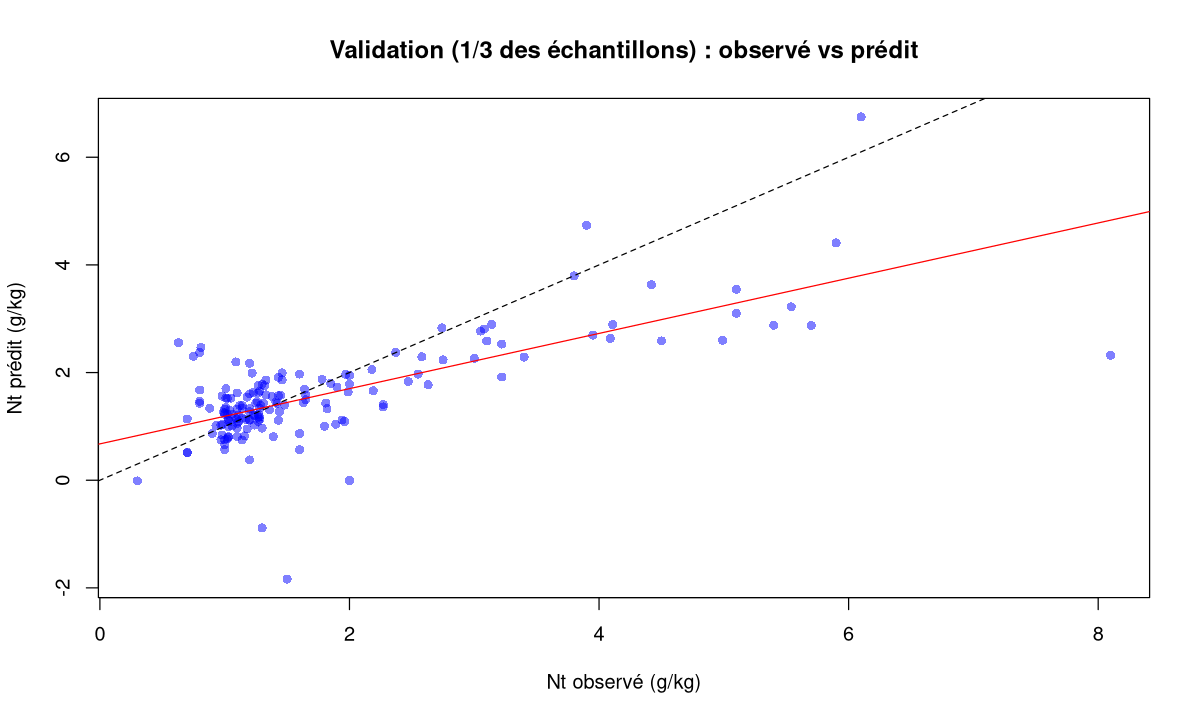

In [5]:
# Graphe observé vs prédit en validation : les points doivent être proches de la droite y = x
plot(y[idx_val], y_hat_val, pch = 16, col = rgb(0, 0, 1, 0.5),
     xlab = "Nt observé (g/kg)", ylab = "Nt prédit (g/kg)",
     main = "Validation (1/3 des échantillons) : observé vs prédit")
abline(0, 1, lty = 2)                                  # droite idéale y = x
abline(lm(c(y_hat_val) ~ y[idx_val]), col = "red")     # droite de régression des prédictions

Les sols riches en azote sont en général **sous-estimés** : la droite de régression des prédictions (en rouge) a une pente inférieure à 1, ce qui « tasse » les prédictions vers la moyenne. Ce type de graphe complète toujours les indicateurs numériques.

### Exercice 1.1 : découpage ½ – ½
Refais le découpage avec la proportion **½ – ½** (même graine `set.seed(1001)`), recalibre le modèle à 20 longueurs d'onde sur la nouvelle moitié de calibration et calcule les performances en calibration et en validation avec `perf_pred()`. Les conclusions changent-elles ?

In [6]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
set.seed(1001)
cal2 <- sample(1:n, size = round(n / 2))
val2 <- setdiff(1:n, cal2)
v2   <- order(abs(cor(X[cal2, ], y[cal2]))[, 1], decreasing = TRUE)[1:20]
m2   <- lm(y[cal2] ~ X[cal2, v2])
round(rbind(calibration = perf_pred(y[cal2], fitted(m2)),
            validation  = perf_pred(y[val2], cbind(1, X[val2, v2]) %*% coef(m2))), 3)
```

Les performances de calibration restent supérieures à celles de validation. Les valeurs exactes changent avec le découpage : avec moins d'échantillons en calibration, l'estimation de β est un peu moins précise ; avec plus d'échantillons en validation, la mesure de l'erreur est plus fiable. C'est le compromis qui guide le choix des proportions.

</details>

### Exercice 1.2 : la fonction `perf_pred()` à la main
Sans utiliser `perf_pred()`, calcule le biais et le RMSE de la validation de la section 1.1 (`y[idx_val]` et `y_hat_val`). Vérifie ensuite numériquement la relation $\text{RMSE}^2 \approx \text{biais}^2 + \text{SEP}^2$.

In [7]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
e <- c(y_hat_val) - y[idx_val]
biais <- mean(e)
rmse  <- sqrt(mean(e^2))
sep   <- sd(e)                 # sd() divise par n - 1 et retire la moyenne (le biais)
c(biais = biais, RMSE = rmse, SEP = sep)
c(RMSE2 = rmse^2, biais2_plus_SEP2 = biais^2 + sep^2)
```

L'erreur quadratique se décompose en une part **systématique** (le biais) et une part **aléatoire** (le SEP). L'égalité n'est qu'approchée parce que le SEP divise par $n - 1$ et le RMSE par $n$. Un biais important signale par exemple un décalage entre les populations de calibration et de validation (voir le fichier de validation des acides gras en partie 0).

</details>

## 1.3 Un seul jeu de validation suffit-il ?

Le syllabus met en garde : l'utilisation d'un **seul** fichier de validation **peut ne pas être représentative** de la population, en particulier par manque de données, donc de variabilité. Vérifions-le en répétant le découpage 2/3 – 1/3 avec 100 graines différentes.

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  0.569   0.707   0.772   0.782   0.842   1.577 

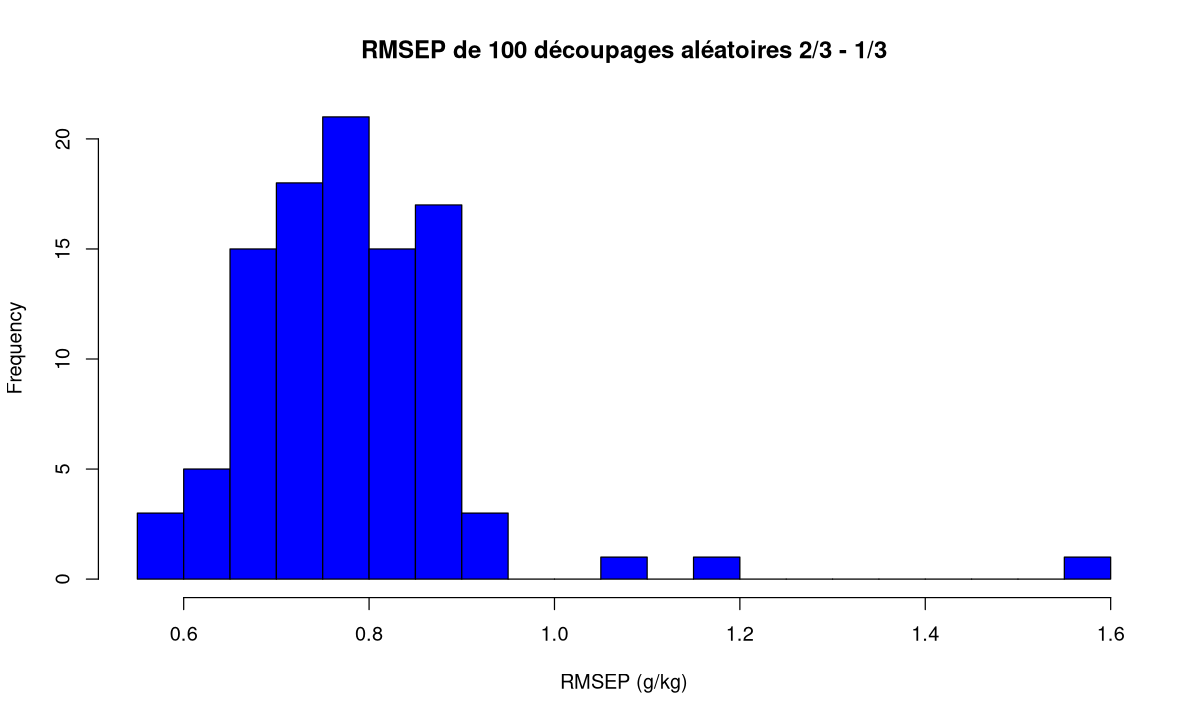

In [8]:
# Fonction : RMSEP d'un découpage aléatoire 2/3 - 1/3 (modèle à p longueurs d'onde)
rmsep_split <- function(seed, p = 20) {
  set.seed(seed)
  cal <- sample(1:n, size = round(2/3 * n)); val <- setdiff(1:n, cal)
  v <- order(abs(cor(X[cal, ], y[cal]))[, 1], decreasing = TRUE)[1:p]
  m <- lm(y[cal] ~ X[cal, v])
  sqrt(mean((y[val] - cbind(1, X[val, v]) %*% coef(m))^2))
}
rmsep_100 <- sapply(1:100, rmsep_split)
round(summary(rmsep_100), 3)
hist(rmsep_100, breaks = 20, col = "blue", xlab = "RMSEP (g/kg)",
     main = "RMSEP de 100 découpages aléatoires 2/3 - 1/3")

Selon le hasard du découpage, le RMSEP du **même** modèle varie de 0.57 à 1.58 g/kg, soit presque du simple au triple. Conclure à partir d'un seul découpage peut donc être trompeur : c'est la motivation de la **validation croisée** (section 1.5), qui combine **plusieurs** jeux de validation.

> **Complément** : deux autres techniques de validation interne sont citées par le syllabus.
> - Le **jackknife** retire tour à tour chaque observation (ou chaque groupe), réestime le modèle et étudie la variabilité des estimations obtenues ; son principe est très proche de la validation croisée *leave-one-out*.
> - Le **bootstrap** tire $n$ observations **avec remise** (`sample(1:n, replace = TRUE)`) pour créer de nombreux jeux de calibration ; les observations jamais tirées (environ 37 %) servent de validation. Il sera détaillé au module 4 (*Random Forest*).

### Exercice 1.3 : variabilité selon la taille du jeu de validation
Modifie `rmsep_split()` pour qu'elle accepte un argument `prop_cal` (proportion de calibration), puis compare l'écart-type des RMSEP obtenus sur 100 graines pour `prop_cal = 0.9` et `prop_cal = 0.5`. Quelle proportion donne l'estimation la plus **stable** de l'erreur ? Pourquoi ?

In [9]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
rmsep_split2 <- function(seed, prop_cal, p = 20) {
  set.seed(seed)
  cal <- sample(1:n, size = round(prop_cal * n)); val <- setdiff(1:n, cal)
  v <- order(abs(cor(X[cal, ], y[cal]))[, 1], decreasing = TRUE)[1:p]
  m <- lm(y[cal] ~ X[cal, v])
  sqrt(mean((y[val] - cbind(1, X[val, v]) %*% coef(m))^2))
}
r90 <- sapply(1:100, rmsep_split2, prop_cal = 0.9)
r50 <- sapply(1:100, rmsep_split2, prop_cal = 0.5)
round(rbind(prop_0.9 = c(moyenne = mean(r90), ecart_type = sd(r90)),
            prop_0.5 = c(moyenne = mean(r50), ecart_type = sd(r50))), 3)
```

Avec 90 % en calibration, le jeu de validation ne compte qu'une cinquantaine d'échantillons : le RMSEP dépend fortement des quelques sols tirés, donc il est **beaucoup plus variable**. Avec 50 %, l'erreur est mesurée sur plus de 240 échantillons et elle est plus stable (même si le modèle, calibré sur moins de données, peut être un peu moins bon). C'est l'illustration du compromis évoqué par le syllabus.

</details>

## 1.4 Taille du jeu d'apprentissage

La taille du jeu de calibration conditionne la **robustesse** de l'équation de prédiction. Selon le syllabus, sa taille idéale est celle :
- **en dessous** de laquelle le modèle obtenu en calibration ne s'ajuste pas bien aux données de validation ;
- **au-delà** de laquelle l'erreur de validation ne diminue plus significativement.

La **Fig. 1** du syllabus représente l'erreur en fonction de la taille du jeu de données :
- un **petit** jeu de calibration peut donner une erreur de calibration **faible**, mais une erreur de validation **élevée** : le modèle n'est pas généralisable ;
- un jeu de calibration **plus grand** donne une erreur de calibration **plus élevée** (toute la variabilité ne peut pas être prise en compte), mais l'erreur de validation s'en rapproche : le modèle est plus **généralisable**, donc plus efficace ;
- à un moment, les erreurs de calibration et de validation **convergent**. Cette propriété n'est pas vérifiée pour tous les modèles.

On reproduit cette figure : un jeu de validation **fixe** (1/3 des sols), et des jeux de calibration de taille croissante tirés dans les 2/3 restants. Pour chaque taille, on répète le tirage 20 fois et on garde la **médiane** des erreurs.

In [10]:
set.seed(1001)
val_fixe <- sample(1:n, round(n / 3))        # jeu de validation fixe
reserve  <- setdiff(1:n, val_fixe)           # réserve dans laquelle on tire la calibration

erreurs <- function(tr, te, p = 20) {
  v <- order(abs(cor(X[tr, ], y[tr]))[, 1], decreasing = TRUE)[1:p]
  m <- lm(y[tr] ~ X[tr, v])
  c(cal = sqrt(mean(resid(m)^2)),
    val = sqrt(mean((y[te] - cbind(1, X[te, v]) %*% coef(m))^2)))
}
tailles <- c(30, 40, 60, 80, 120, 160, 200, 250, length(reserve))
courbe <- t(sapply(tailles, function(s) {
  rep20 <- replicate(20, erreurs(sample(reserve, s), val_fixe))
  c(n_cal = s, RMSE_cal = median(rep20["cal", ]), RMSE_val = median(rep20["val", ]))
}))
round(courbe, 3)

n_cal,RMSE_cal,RMSE_val
30,0.316,1.182
40,0.381,1.123
60,0.476,0.795
80,0.564,0.801
120,0.614,0.681
160,0.696,0.670
200,0.682,0.665
250,0.734,0.649
323,0.733,0.636


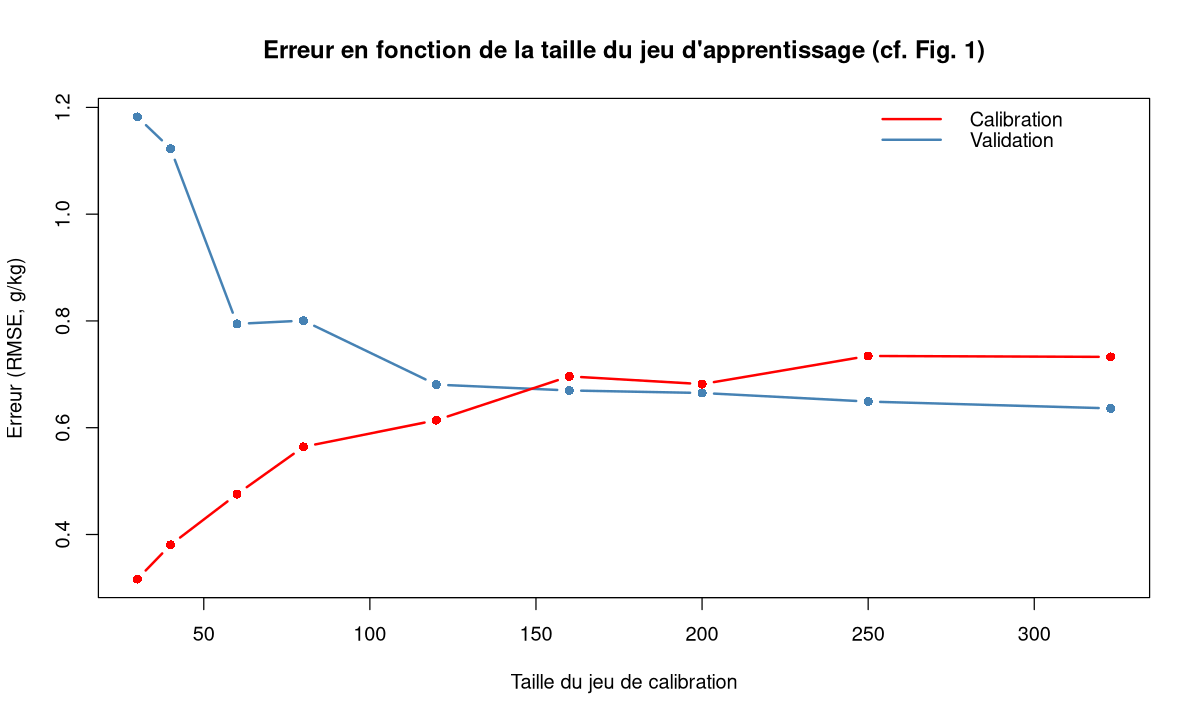

In [11]:
plot(courbe[, "n_cal"], courbe[, "RMSE_val"], type = "b", pch = 16, col = "steelblue", lwd = 2,
     ylim = range(courbe[, -1]), xlab = "Taille du jeu de calibration",
     ylab = "Erreur (RMSE, g/kg)", main = "Erreur en fonction de la taille du jeu d'apprentissage (cf. Fig. 1)")
lines(courbe[, "n_cal"], courbe[, "RMSE_cal"], type = "b", pch = 16, col = "red", lwd = 2)
legend("topright", c("Calibration", "Validation"), col = c("red", "steelblue"), lwd = 2, bty = "n")

On retrouve exactement l'allure de la Fig. 1 : avec 30 sols (pour 21 coefficients à estimer), l'erreur de calibration est très faible mais l'erreur de validation est énorme ; à mesure que la calibration grandit, les deux courbes se rapprochent. Au-delà d'environ 150 à 200 sols, l'erreur de validation ne baisse presque plus : c'est l'ordre de grandeur de la **taille idéale** pour ce modèle.

> **Complément** : la taille nécessaire dépend du **nombre de paramètres** à estimer. Une règle empirique, rappelée dans la résolution officielle des acides gras, demande environ **10 observations par coefficient** de régression. Avec 21 coefficients, on vise donc au moins 200 observations, ce qui correspond bien à la zone où la courbe de validation se stabilise.

### Exercice 1.4 : un modèle plus simple
Refais la courbe d'apprentissage avec un modèle à **5** longueurs d'onde au lieu de 20 (argument `p` de la fonction `erreurs()`). Comment évoluent l'écart entre calibration et validation pour les petites tailles, et la taille à partir de laquelle la validation se stabilise ?

In [12]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
courbe5 <- t(sapply(tailles, function(s) {
  rep20 <- replicate(20, erreurs(sample(reserve, s), val_fixe, p = 5))
  c(n_cal = s, RMSE_cal = median(rep20["cal", ]), RMSE_val = median(rep20["val", ]))
}))
round(courbe5, 3)
plot(courbe5[, "n_cal"], courbe5[, "RMSE_val"], type = "b", pch = 16, col = "steelblue",
     ylim = range(courbe5[, -1]), xlab = "Taille du jeu de calibration", ylab = "RMSE (g/kg)")
lines(courbe5[, "n_cal"], courbe5[, "RMSE_cal"], type = "b", pch = 16, col = "red")
```

Avec seulement 6 coefficients, l'écart entre calibration et validation est beaucoup plus faible dès 30 à 40 sols, et la validation se stabilise beaucoup plus tôt : un modèle simple a besoin de moins de données. En revanche, son erreur finale est plus élevée que celle du modèle à 20 longueurs d'onde (sous-ajustement) : c'est le compromis biais-variance, qui reviendra avec le choix du nombre de composantes en PCR et en PLS.

</details>

## 1.5 La validation croisée

L'utilisation d'un jeu de validation permet d'évaluer la robustesse du modèle, mais les performances dépendent fortement de la qualité de **ce** jeu de validation (section 1.3). L'idée de la **validation croisée** (*cross-validation*) est de travailler avec **plusieurs** jeux de validation et de combiner les résultats obtenus pour chacun.

Deux types existent :

> **Définition**
> - **Validation croisée complète** (*full cross-validation*), aussi appelée ***leave-one-out*** (LOO) : on retire **une** observation, on développe le modèle sur les données restantes, puis on l'applique à l'observation retirée. On répète autant de fois qu'il y a d'observations. Les prédictions obtenues servent à calculer le r² et le RMSE de validation croisée.
> - **Validation croisée à k groupes** (*k-fold cross-validation*) : le jeu initial est divisé **au hasard** en **k groupes**. Au premier tour, le premier groupe est retiré, le modèle est construit sur les autres, puis appliqué aux observations écartées. On répète autant de fois qu'il y a de groupes. Les prédictions servent à calculer le RMSE et le r² de validation croisée. Par défaut, on utilise souvent **10 groupes**.

L'avantage : chaque observation est prédite par un modèle qui **ne l'a pas utilisée**. Mais les données ne sont pas pour autant **complètement indépendantes** : avec des données répétées, les données d'un même individu peuvent se trouver à la fois dans la calibration et dans la validation croisée. La validation croisée n'est donc **pas** une validation externe : c'est une **validation interne**.

### Programmer une validation croisée k-fold
On écrit une fonction générale : elle reçoit les **groupes** (*folds*) et une fonction qui **calibre puis prédit**. Ainsi, on pourra la réutiliser avec n'importe quel modèle.

In [13]:
# Modèle du module 1 : sélection des p longueurs d'onde les plus corrélées, puis lm
# (la sélection est refaite à chaque calibration : voir la section 1.8 pour comprendre pourquoi)
ajuste_predit <- function(X_tr, y_tr, X_te, p = 20) {
  v <- order(abs(cor(X_tr, y_tr))[, 1], decreasing = TRUE)[1:p]
  m <- lm(y_tr ~ X_tr[, v])
  c(cbind(1, X_te[, v, drop = FALSE]) %*% coef(m))
}

# Validation croisée générale : renvoie une prédiction "hors calibration" pour chaque observation
cv_predictions <- function(X, y, groupes, fun, ...) {
  pred <- rep(NA, length(y))
  for (g in unique(groupes)) {
    test <- groupes == g                                   # le groupe retiré
    pred[test] <- fun(X[!test, ], y[!test], X[test, , drop = FALSE], ...)
  }
  pred
}

set.seed(1001)
k <- 10
groupes10 <- sample(rep(1:k, length.out = n))   # attribue chaque sol à un des 10 groupes
table(groupes10)                                # environ 48-49 sols par groupe
pred_cv10 <- cv_predictions(X, y, groupes10, ajuste_predit)
round(perf_pred(y, pred_cv10), 3)

groupes10
 1  2  3  4  5  6  7  8  9 10 
49 49 49 49 49 48 48 48 48 48 

R2   RMSE  biais    SEP    RPD 
 0.599  0.739 -0.005  0.740  1.578

> **Fonction R** : `rep(x, times, each, length.out)` puis `sample()`
>
> `rep(1:k, length.out = n)` répète la séquence 1, 2, …, k jusqu'à obtenir n valeurs (groupes de tailles égales à une unité près) ; `sample()` mélange ensuite ces étiquettes pour que les groupes soient **aléatoires**. Le package `pls` fournit la même chose avec `cvsegments(n, k, type = "random")`, qui renvoie une **liste** d'indices (un élément par groupe), utilisée dans ton `homework2.R`.

In [14]:
# Équivalent avec pls::cvsegments() : une liste de k vecteurs d'indices
set.seed(1001)
segments <- cvsegments(n, k = 10, type = "random")
length(segments); sapply(segments, length)
# Conversion de la liste en vecteur de groupes, pour réutiliser cv_predictions()
groupes_seg <- rep(NA, n)
for (g in seq_along(segments)) groupes_seg[segments[[g]]] <- g
round(perf_pred(y, cv_predictions(X, y, groupes_seg, ajuste_predit)), 3)

[1] 10

V1  V2  V3  V4  V5  V6  V7  V8  V9 V10 
 49  49  49  49  49  48  48  48  48  48

R2  RMSE biais   SEP   RPD 
0.587 0.752 0.001 0.752 1.552

> **Fonction R** : `cvsegments(N, k, length.seg, type = c("random", "consecutive", "interleaved"))` (package `pls`)
>
> | `type` | Construction des k segments |
> |---|---|
> | `"random"` | échantillons répartis au hasard (le cas habituel) |
> | `"consecutive"` | blocs d'échantillons consécutifs (1–49, 50–98…) : utile si les lignes sont ordonnées dans le temps ou par origine |
> | `"interleaved"` | un échantillon sur k (1, 11, 21… ; 2, 12, 22…) |
>
> Renvoie une liste de k vecteurs d'indices. Avec `k = N`, chaque segment contient un seul échantillon : c'est le *leave-one-out*.

### La validation croisée *leave-one-out*

Avec le LOO, il y a autant de groupes que d'observations : il suffit de donner à chaque sol son propre groupe (`groupes = 1:n`). On calibre donc 485 modèles.

In [15]:
pred_loo <- cv_predictions(X, y, 1:n, ajuste_predit)
round(rbind(`10-fold` = perf_pred(y, pred_cv10), LOO = perf_pred(y, pred_loo)), 3)

,R2,RMSE,biais,SEP,RPD
10-fold,0.599,0.739,-0.005,0.740,1.578
LOO,0.596,0.742,-0.001,0.743,1.571


Les deux validations croisées donnent des résultats proches. Le LOO est **déterministe** (pas de tirage au hasard) mais **coûteux** (n modèles) ; le k-fold demande seulement k modèles, mais son résultat dépend du découpage aléatoire.

> **Complément** : pour une régression `lm()` dont les variables sont **fixées à l'avance**, le LOO se calcule **sans refaire n régressions**. Le résidu de LOO de l'observation $i$ vaut $e_i / (1 - h_{ii})$, où $h_{ii}$ est le **levier** (*leverage*, `hatvalues()`, vu au module 1 avec le graphe *Residuals vs Leverage*). La somme de leurs carrés s'appelle le **PRESS** (*PRediction Error Sum of Squares*), une quantité que l'on retrouvera dans le critère Q² de la PLS (partie 4).

In [16]:
# Vérification de la formule du PRESS sur un modèle à variables fixées
v_fixe <- order(abs(cor(X, y))[, 1], decreasing = TRUE)[1:20]   # sélection fixée une fois pour toutes
m_fixe <- lm(y ~ X[, v_fixe])
press  <- sum((resid(m_fixe) / (1 - hatvalues(m_fixe)))^2)
loo_boucle <- sapply(1:n, function(i) {
  mi <- lm(y[-i] ~ X[-i, v_fixe])
  sum(c(1, X[i, v_fixe]) * coef(mi))
})
c(RMSECV_formule_PRESS = sqrt(press / n), RMSECV_boucle = sqrt(mean((y - loo_boucle)^2)))

RMSECV_formule_PRESS        RMSECV_boucle 
           0.7381371            0.7381371

### Exercice 1.5 : 5-fold contre 10-fold
Calcule les performances en validation croisée **5-fold** (même graine 1001) avec `cv_predictions()` et compare-les au 10-fold et au LOO. Laquelle de ces validations utilise, à chaque tour, le plus petit jeu de calibration ?

In [17]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
set.seed(1001)
groupes5 <- sample(rep(1:5, length.out = n))
pred_cv5 <- cv_predictions(X, y, groupes5, ajuste_predit)
round(rbind(`5-fold` = perf_pred(y, pred_cv5), `10-fold` = perf_pred(y, pred_cv10),
            LOO = perf_pred(y, pred_loo)), 3)
```

En 5-fold, chaque modèle est calibré sur 4/5 des données (388 sols), contre 9/10 en 10-fold (436 sols) et $n - 1$ en LOO (484 sols). En théorie, moins de données de calibration conduit à une erreur un peu plus élevée (le 5-fold tend à être **pessimiste**), et le LOO est le moins biaisé mais le plus variable. Ici, les trois RMSECV (0.730, 0.739, 0.742) sont pourtant quasi identiques, et l'ordre est même inversé : la différence est plus petite que la variabilité due au tirage des groupes (écart-type d'environ 0.02 entre graines, voir la validation croisée répétée ci-dessous). Le 10-fold reste le compromis recommandé par le syllabus (« by default, we often use 10 groups »).

</details>

### La validation croisée répétée

Un k-fold dépend du découpage aléatoire. Pour stabiliser le résultat, on peut le **répéter** avec plusieurs graines et faire la moyenne, comme dans ton `homework2.R` (section 5 : 10-fold répété 20 fois).

In [18]:
rmsecv_rep <- sapply(1:20, function(s) {
  set.seed(s)
  g <- sample(rep(1:10, length.out = n))
  sqrt(mean((y - cv_predictions(X, y, g, ajuste_predit))^2))
})
round(c(moyenne = mean(rmsecv_rep), ecart_type = sd(rmsecv_rep),
        min = min(rmsecv_rep), max = max(rmsecv_rep)), 4)

moyenne ecart_type        min        max 
    0.7499     0.0196     0.7287     0.8267

L'écart-type du RMSECV entre répétitions est bien plus faible que celui du RMSEP d'un découpage unique 2/3 – 1/3 (section 1.3) : la validation croisée donne une estimation **plus stable** de l'erreur, car chaque observation sert une fois en validation.

## 1.6 Choisir la complexité d'un modèle par validation croisée

Le syllabus décrit la **Fig. 2** : si l'on inclut davantage de variables potentiellement explicatives, le r² de **calibration** a tendance à augmenter (et le RMSE de calibration à diminuer). En revanche, le r² de **validation croisée** augmente lui aussi jusqu'à un certain moment, **puis diminue** : c'est le **surapprentissage**. L'information ajoutée est trop spécifique au jeu de calibration et n'est plus pertinente pour de nouvelles données.

L'un des intérêts majeurs de la validation croisée est donc de **déterminer le nombre de variables le plus approprié**.

In [19]:
nb_vars <- c(1, 2, 3, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 400)
set.seed(1001)
g10 <- sample(rep(1:10, length.out = n))
fig2 <- t(sapply(nb_vars, function(p) {
  # calibration : modèle sur toutes les données
  v <- order(abs(cor(X, y))[, 1], decreasing = TRUE)[1:p]
  m <- lm(y ~ X[, v])
  # validation croisée 10-fold (sélection refaite dans chaque groupe)
  pcv <- suppressWarnings(cv_predictions(X, y, g10, ajuste_predit, p = p))
  c(p = p, R2_cal = summary(m)$r.squared, R2_cv = cor(y, pcv)^2,
    RMSE_cal = sqrt(mean(resid(m)^2)), RMSE_cv = sqrt(mean((y - pcv)^2)))
}))
round(fig2, 3)

p,R2_cal,R2_cv,RMSE_cal,RMSE_cv
1,0.446,0.438,0.867,0.874
2,0.446,0.443,0.867,0.870
3,0.483,0.470,0.838,0.849
5,0.503,0.478,0.821,0.842
10,0.530,0.520,0.799,0.808
20,0.652,0.599,0.688,0.739
30,0.687,0.592,0.652,0.752
50,0.776,0.640,0.552,0.708
75,0.830,0.694,0.480,0.652
100,0.839,0.667,0.467,0.684


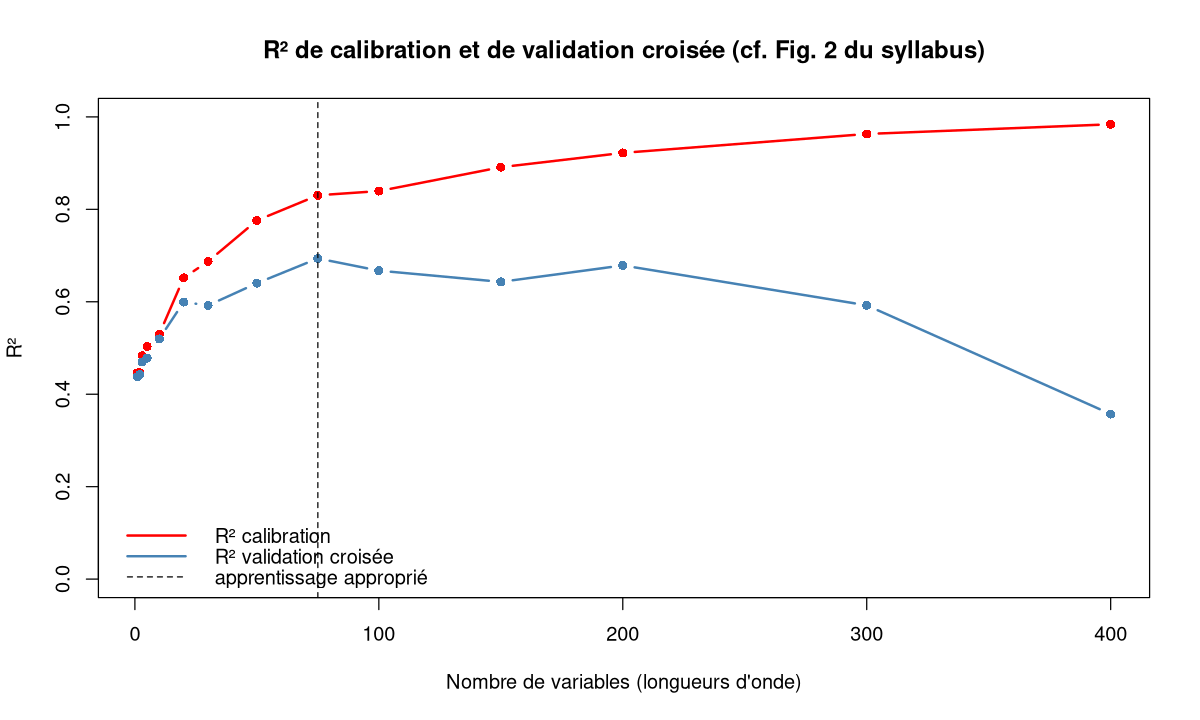

In [20]:
plot(fig2[, "p"], fig2[, "R2_cal"], type = "b", pch = 16, col = "red", lwd = 2, ylim = c(0, 1),
     xlab = "Nombre de variables (longueurs d'onde)", ylab = "R²",
     main = "R² de calibration et de validation croisée (cf. Fig. 2 du syllabus)")
lines(fig2[, "p"], fig2[, "R2_cv"], type = "b", pch = 16, col = "steelblue", lwd = 2)
best <- fig2[which.max(fig2[, "R2_cv"]), "p"]
abline(v = best, lty = 2)
legend("bottomleft", c("R² calibration", "R² validation croisée", "apprentissage approprié"),
       col = c("red", "steelblue", "black"), lty = c(1, 1, 2), lwd = c(2, 2, 1), bty = "n")

La figure reproduit la Fig. 2 du syllabus : le R² de calibration monte jusqu'à près de 0.98 avec 400 longueurs d'onde, alors que le R² de validation croisée culmine vers 75 longueurs d'onde (environ 0.70), puis **s'effondre**. Le modèle à 400 variables a « appris par cœur » les sols de calibration (R²cv 0.36). La ligne pointillée marque l'« apprentissage approprié ».

> **Attention** : même au meilleur nombre de variables, cette approche reste fragile. Les longueurs d'onde sont fortement **colinéaires**, et 75 coefficients pour 485 échantillons violent la règle des 10 observations par coefficient. C'est précisément pour éviter ce type de modèle que la PCR et la PLS remplacent les 700 longueurs d'onde par **quelques composantes**. Le nombre de composantes sera lui aussi choisi par validation croisée.

### Exercice 1.6 : choisir selon le RMSE plutôt que le R²
À partir de la matrice `fig2`, trace le RMSE de calibration et le RMSE de validation croisée en fonction du nombre de variables. Le nombre de variables qui **minimise** le RMSECV est-il le même que celui qui **maximise** le R²cv ?

In [21]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
plot(fig2[, "p"], fig2[, "RMSE_cv"], type = "b", pch = 16, col = "steelblue",
     ylim = range(fig2[, c("RMSE_cal", "RMSE_cv")]), log = "y",
     xlab = "Nombre de variables", ylab = "RMSE (g/kg, échelle log)")
lines(fig2[, "p"], fig2[, "RMSE_cal"], type = "b", pch = 16, col = "red")
legend("topleft", c("RMSE calibration", "RMSE validation croisée"),
       col = c("red", "steelblue"), lwd = 1, bty = "n")
c(p_min_RMSEcv = fig2[which.min(fig2[, "RMSE_cv"]), "p"],
  p_max_R2cv   = fig2[which.max(fig2[, "R2_cv"]), "p"])
```

Le RMSE de calibration diminue sans cesse, alors que le RMSECV passe par un minimum puis remonte fortement (d'où l'échelle logarithmique). Ici, les deux critères désignent le même nombre de variables. Ce n'est pas garanti en général, car le R² (corrélation au carré) ignore le biais, alors que le RMSE le prend en compte : le RMSECV est le critère le plus utilisé pour choisir le nombre de composantes en PCR et en PLS.

</details>

## 1.7 La validation croisée dans les packages `pls` et `glmnet`

En pratique, on n'écrit pas la boucle soi-même : les fonctions de modélisation du module intègrent la validation croisée.

### Dans `pls` : l'argument `validation`
Les fonctions `pcr()` et `plsr()` (parties 3 et 4) acceptent l'argument `validation = "CV"` (10-fold aléatoire par défaut) ou `validation = "LOO"`. Le nombre de **composantes** joue alors le rôle du nombre de variables de la Fig. 2. Aperçu avec une PLS sur les sols :

In [22]:
dat <- data.frame(Nt = y)
dat$spectra <- X
set.seed(1001)
pls_cv <- plsr(Nt ~ spectra, data = dat, ncomp = 30, scale = TRUE, validation = "CV")
# RMSE de calibration ("train"), de validation croisée ("CV") et CV ajustée ("adjCV")
rm <- RMSEP(pls_cv, estimate = c("train", "CV", "adjCV"))
round(rm$val[, 1, c(1, 2, 6, 11, 16, 21, 31)], 3)   # (Intercept), 1, 5, 10, 15, 20 et 30 composantes

,(Intercept),1 comps,5 comps,10 comps,15 comps,20 comps,30 comps
train,1.165,0.908,0.575,0.477,0.440,0.412,0.348
CV,1.168,0.921,0.597,0.539,0.534,0.555,0.585
adjCV,1.168,0.920,0.596,0.536,0.528,0.547,0.570


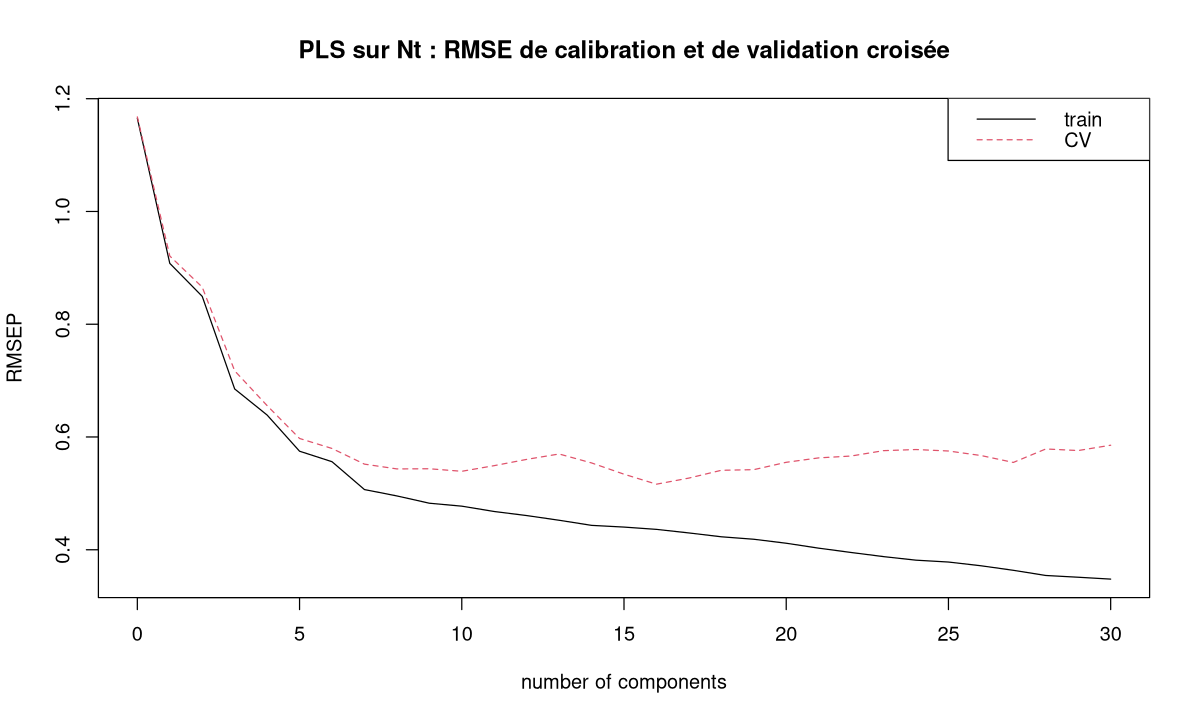

In [23]:
validationplot(pls_cv, val.type = "RMSEP", estimate = c("train", "CV"),
               legendpos = "topright", main = "PLS sur Nt : RMSE de calibration et de validation croisée")

Même comportement qu'avec le nombre de variables : le RMSE de calibration (*train*) diminue sans cesse avec le nombre de composantes, tandis que le RMSE de validation croisée (*CV*) atteint un plancher puis remonte légèrement.

> **Fonction R** : arguments de validation de `pcr()` / `plsr()` (package `pls`)
>
> | Argument | Rôle |
> |---|---|
> | `validation = "none"` | pas de validation (défaut) |
> | `validation = "CV"` | validation croisée ; 10 segments aléatoires par défaut |
> | `validation = "LOO"` | *leave-one-out* |
> | `segments = 5` ou `segments = cvsegments(...)` | nombre de segments, ou segments fournis explicitement |
> | `segment.type = "random"` | type de segments (`"consecutive"`, `"interleaved"`) |
>
> Les performances s'extraient avec `RMSEP(mod, estimate = c("train", "CV", "adjCV"))` et `R2(mod, ...)`. L'élément `$val` est un tableau à 3 dimensions : estimation × variable réponse × nombre de composantes (la première « composante » est le modèle réduit à l'intercept). `"adjCV"` est un RMSECV corrigé du biais lié à la validation croisée. Détails en partie 3.

### Dans `glmnet` : `cv.glmnet()`
Au module 1, le paramètre λ des régressions pénalisées était choisi « par tests successifs » sur un jeu de validation. La fonction `cv.glmnet()` le fait par **validation croisée** (10-fold par défaut). La résolution officielle des acides gras l'utilise (section 5).

lambda.min  lambda.1se 
0.007782932 0.012982713

,RMSECV,nb_variables
lambda.min,0.668,18
lambda.1se,0.718,20


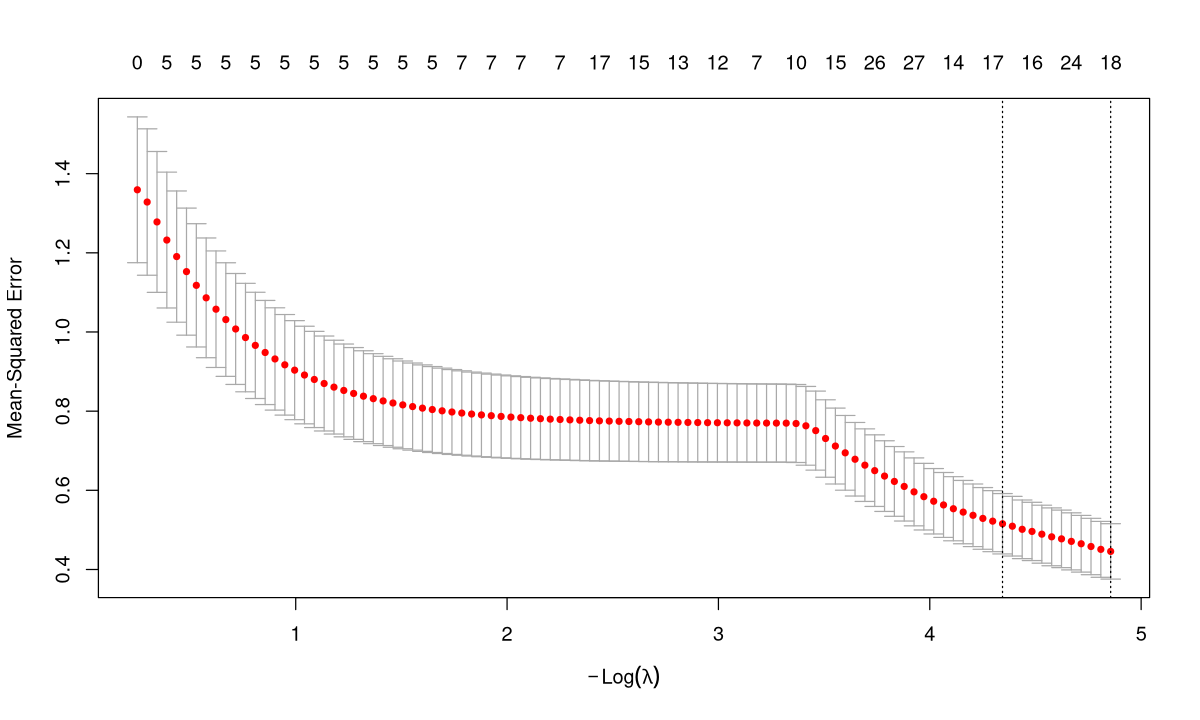

In [24]:
set.seed(1001)
lasso_cv <- cv.glmnet(x = X, y = y, alpha = 1, family = "gaussian", nfolds = 10)
c(lambda.min = lasso_cv$lambda.min, lambda.1se = lasso_cv$lambda.1se)
# Erreur de validation croisée (MSE) et nombre de variables retenues pour ces deux lambdas
i_min <- which(lasso_cv$lambda == lasso_cv$lambda.min)
i_1se <- which(lasso_cv$lambda == lasso_cv$lambda.1se)
round(rbind(lambda.min = c(RMSECV = sqrt(lasso_cv$cvm[i_min]), nb_variables = unname(lasso_cv$nzero[i_min])),
            lambda.1se = c(RMSECV = sqrt(lasso_cv$cvm[i_1se]), nb_variables = unname(lasso_cv$nzero[i_1se]))), 3)
plot(lasso_cv)

> **Fonction R** : `cv.glmnet(x, y, alpha, lambda = NULL, nfolds = 10, family = "gaussian", type.measure = "mse", ...)`
>
> | Élément du résultat | Contenu |
> |---|---|
> | `lambda` | la grille de λ testée |
> | `cvm` | erreur moyenne de validation croisée (MSE) pour chaque λ ; $\sqrt{\text{cvm}}$ = RMSECV |
> | `cvsd` | écart-type estimé de `cvm` |
> | `cvup`, `cvlo` | `cvm + cvsd` et `cvm - cvsd` (barres d'erreur du graphe) |
> | `nzero` | nombre de coefficients non nuls pour chaque λ |
> | `lambda.min` | λ qui donne le plus petit `cvm` |
> | `lambda.1se` | le plus grand λ (modèle le plus **parcimonieux**) dont l'erreur reste à moins d'**un écart-type** du minimum |
> | `glmnet.fit` | le modèle `glmnet` ajusté sur toutes les données |
>
> Prédiction : `predict(cv, newx = X_nouveau, s = "lambda.1se")` (ou une valeur numérique de λ). Sur le graphe, les deux pointillés verticaux marquent `log(lambda.min)` et `log(lambda.1se)` ; les nombres en haut sont les `nzero`.

La règle « **un écart-type** » (`lambda.1se`) privilégie un modèle plus **pénalisé**, dont l'erreur n'est pas significativement plus grande que le minimum. En général, cela réduit le nombre de variables retenues par le Lasso. Ici pourtant, `lambda.1se` garde 20 longueurs d'onde contre 18 pour `lambda.min` : avec des variables très colinéaires, le Lasso peut échanger une longueur d'onde contre deux voisines quand λ change, et le nombre de coefficients non nuls n'évolue pas toujours dans le même sens que λ. Les coefficients, eux, sont bien plus petits (plus rétrécis). Le même raisonnement « un écart-type » existe dans `pls` avec `selectNcomp(mod, method = "onesigma")` (partie 3).

### Exercice 1.7 : Ridge en validation croisée
Refais la validation croisée avec une régression **Ridge** (`alpha = 0`, même graine). Compare le RMSECV obtenu à `lambda.min` avec celui du Lasso et avec le meilleur RMSECV de la PLS (`min(rm$val["CV", 1, -1])`). Combien de variables le Ridge conserve-t-il ? Vérifie enfin si `lambda.min` se trouve **au bord** de la grille de λ testée et, si c'est le cas, recommence avec une grille qui descend jusqu'à $10^{-5}$.

In [25]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
set.seed(1001)
ridge_cv <- cv.glmnet(x = X, y = y, alpha = 0, family = "gaussian", nfolds = 10)
j <- which(ridge_cv$lambda == ridge_cv$lambda.min)
round(c(RMSECV_ridge = sqrt(ridge_cv$cvm[j]), nb_var_ridge = unname(ridge_cv$nzero[j]),
        RMSECV_lasso = sqrt(lasso_cv$cvm[i_min]),
        RMSECV_pls_min = min(rm$val["CV", 1, -1])), 3)
# lambda.min est-il la plus petite valeur de la grille ?
c(lambda.min = ridge_cv$lambda.min, plus_petit_lambda = min(ridge_cv$lambda))

# Grille étendue vers les petites valeurs
set.seed(1001)
ridge_cv2 <- cv.glmnet(x = X, y = y, alpha = 0, family = "gaussian", nfolds = 10,
                       lambda = exp(seq(log(10), log(1e-5), length.out = 60)))
c(lambda.min = ridge_cv2$lambda.min, RMSECV = sqrt(min(ridge_cv2$cvm)))
```

Le Ridge garde **toutes** les longueurs d'onde (700) : il rétrécit les coefficients sans jamais les annuler (module 1, partie 6). Avec la grille par défaut, son RMSECV (0.87 g/kg) est même plus mauvais que la régression sur 20 longueurs d'onde. Mais `lambda.min` est **égal au plus petit λ de la grille** : l'optimum se trouve au-delà de la zone explorée. Avec une grille qui descend jusqu'à $10^{-5}$, le RMSECV tombe à environ 0.55 g/kg, proche de la PLS (0.52) et meilleur que le Lasso (0.67).

À retenir : quand le λ optimal est au bord de la grille, il faut **élargir la grille**. C'est pour cette raison que les résolutions officielles fournissent leur propre séquence de λ, jusqu'à $10^{-5}$ ou $10^{-6}$. La comparaison complète des modèles sera faite en partie 5.

</details>

## 1.8 Le piège de la fuite d'information

Pour qu'une validation (croisée ou non) soit honnête, **toutes** les étapes qui utilisent y doivent être refaites **à l'intérieur** de chaque calibration : choix des variables, choix d'un seuil, retrait d'outliers, réglage d'un paramètre… Sinon, l'information du jeu de validation « fuit » dans le modèle (*data leakage*), et les performances sont **trop optimistes**.

C'est pour cette raison que la fonction `ajuste_predit()` refait la sélection des longueurs d'onde dans chaque groupe, et que ton `homework2.R` (section 6) retire les outliers spectraux **uniquement de la partie calibration** de chaque segment de validation croisée.

Démonstration spectaculaire sur des données **sans aucun lien** : y et les 1 000 variables X sont du pur bruit aléatoire.

In [26]:
set.seed(2)
n_b <- 100; p_b <- 1000
X_bruit <- matrix(rnorm(n_b * p_b), n_b)   # 1000 variables de bruit
y_bruit <- rnorm(n_b)                       # y sans aucun lien avec X
g5 <- sample(rep(1:5, length.out = n_b))

# Version FAUTIVE : les 10 variables "les plus corrélées" sont choisies sur TOUTES les données
top10 <- order(abs(cor(X_bruit, y_bruit)), decreasing = TRUE)[1:10]
fautive <- cv_predictions(X_bruit[, top10], y_bruit, g5,
                          function(Xtr, ytr, Xte) c(cbind(1, Xte) %*% coef(lm(ytr ~ Xtr))))
# Version CORRECTE : la sélection est refaite dans chaque groupe
correcte <- cv_predictions(X_bruit, y_bruit, g5, ajuste_predit, p = 10)

round(rbind(fuite = perf_pred(y_bruit, fautive), correcte = perf_pred(y_bruit, correcte)), 3)
sd(y_bruit)   # un modèle inutile (prédire la moyenne) a un RMSE proche de cet écart-type

,R2,RMSE,biais,SEP,RPD
fuite,0.253,0.736,-0.024,0.739,1.146
correcte,0.050,1.120,-0.116,1.119,0.753


[1] 0.8428862

Avec la version fautive, la validation croisée annonce un R² d'environ 0.25 et un RMSE **inférieur** à l'écart-type de y : on croirait avoir trouvé un modèle utile… sur du bruit pur ! La version correcte révèle la vérité : R² quasi nul et RMSE **supérieur** à l'écart-type (RPD < 1), c'est-à-dire pire que de prédire la moyenne.

> **Attention** : la même erreur guette dès qu'une étape « regarde » y avant la validation. Par exemple : sélectionner les longueurs d'onde par corrélation sur tout le jeu (module 1), choisir un nombre de composantes puis annoncer le RMSECV correspondant comme une erreur de prédiction, ou nettoyer les outliers à partir des résidus du modèle. Seule une **validation externe**, sur des données jamais touchées pendant toute la construction du modèle, donne une mesure vraiment indépendante. C'est le rôle du fichier `validation_fatty_acids.csv` (partie 5) et du jeu de test des sols (partie 6).

### Exercice 1.8 : la fuite sur les vraies données
Sur les sols, compare le RMSECV 10-fold (groupes `g10`) d'un modèle à **150** longueurs d'onde : (a) sélectionnées une fois pour toutes sur les 485 sols, puis validées par `cv_predictions()` ; (b) sélectionnées dans chaque groupe avec `ajuste_predit(..., p = 150)`. L'écart est-il aussi spectaculaire que sur le bruit ?

In [27]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
v150 <- order(abs(cor(X, y))[, 1], decreasing = TRUE)[1:150]
pa <- suppressWarnings(cv_predictions(X[, v150], y, g10,
        function(Xtr, ytr, Xte) c(cbind(1, Xte) %*% coef(lm(ytr ~ Xtr)))))
pb <- suppressWarnings(cv_predictions(X, y, g10, ajuste_predit, p = 150))
round(rbind(selection_globale = perf_pred(y, pa), selection_par_groupe = perf_pred(y, pb)), 3)
```

Ici, il n'y a **pas** d'écart notable : la sélection globale donne même un RMSECV légèrement plus élevé (0.720 contre 0.712), simple effet du hasard. Le signal spectral de Nt est fort : les longueurs d'onde réellement liées à Nt sont choisies dans les deux cas, et leur classement change peu d'un groupe à l'autre. La fuite d'information n'est donc pas **toujours** visible. Mais elle n'est jamais sans risque : plus le rapport signal/bruit est faible et plus le nombre de variables candidates est grand, plus elle gonfle les performances, jusqu'à l'extrême de la démonstration sur le bruit. La bonne pratique reste donc de refaire toute étape qui utilise y dans chaque calibration. Les avertissements masqués par `suppressWarnings()` viennent de coefficients `NA` (colinéarité parfaite entre longueurs d'onde voisines).

</details>

## Questions de compréhension

**Q1.** Vrai ou faux : la validation croisée *k-fold* est une validation externe.

**Q2.** Un jeu de données contient 3 prélèvements de lait par vache pour 150 vaches. Pourquoi un découpage aléatoire des 450 lignes en calibration / validation est-il problématique ? Que faudrait-il faire ?

**Q3.** Sur la Fig. 1 du syllabus, pourquoi l'erreur de **calibration** augmente-t-elle avec la taille du jeu de données ?

**Q4.** Le RMSE de calibration d'un modèle vaut 0.30 g/kg et son RMSECV 0.80 g/kg. Que peux-tu en conclure ?

**Q5.** Quelle est la différence entre `lambda.min` et `lambda.1se` dans `cv.glmnet()` ? Lequel donne le modèle le plus parcimonieux ?

**Q6.** Pourquoi faut-il refaire la sélection des variables à l'intérieur de chaque groupe de validation croisée ?

<details>
<summary><b>Voir la réponse</b></summary>

**Q1.** **Faux.** Les prédictions portent sur des données non utilisées pour **ce** modèle, mais elles proviennent du même échantillonnage : avec des données répétées, un même individu peut se trouver en calibration et en validation. La validation croisée est une **validation interne** (syllabus §1.3).

**Q2.** Les 3 prélèvements d'une même vache ne sont pas indépendants : si certains sont en calibration et d'autres en validation, le modèle « connaît » déjà la vache et les performances sont surestimées (dépendance **individuelle**). Il faut découper **par vache** : tirer au hasard des vaches et mettre tous leurs prélèvements du même côté.

**Q3.** Avec peu de données, le modèle peut s'ajuster presque parfaitement à chacune (surapprentissage). Plus le jeu est grand, plus il contient de variabilité que le modèle ne peut pas entièrement prendre en compte : l'erreur de calibration augmente, mais elle devient plus réaliste et se rapproche de l'erreur de validation.

**Q4.** Un écart aussi grand signale un **surapprentissage** : le modèle est trop complexe (trop de variables ou de composantes) pour la quantité de données. Il faut le simplifier, et c'est le RMSECV (0.80) qui donne l'ordre de grandeur de l'erreur attendue sur de nouveaux échantillons.

**Q5.** `lambda.min` minimise l'erreur moyenne de validation croisée ; `lambda.1se` est le plus grand λ dont l'erreur reste à moins d'un écart-type de ce minimum. `lambda.1se` pénalise plus, donc donne le modèle le plus **parcimonieux** (moins de variables pour le Lasso).

**Q6.** Si les variables sont choisies avec toutes les données, y compris celles qui serviront de validation, l'information de la validation « fuit » dans le modèle et les performances sont trop optimistes (jusqu'à trouver un modèle « utile » sur du bruit pur).

</details>

## Récapitulatif

- **Calibration** = estimer le modèle ; **validation** = mesurer ses performances sur d'autres données. Découpage aléatoire (2/3 – 1/3, ½ – ½, 25–50 % en validation) en respectant l'**indépendance** (temporelle, géographique, individuelle).
- **Validation externe** = données complètement indépendantes ; **validation interne** = validation croisée, jackknife, bootstrap.
- Un seul jeu de validation peut ne pas être représentatif : le RMSEP varie fortement d'un découpage à l'autre.
- **Taille du jeu d'apprentissage** (Fig. 1) : l'erreur de calibration augmente, celle de validation diminue, jusqu'à converger ; environ 10 observations par coefficient.
- **Validation croisée** : *leave-one-out* (n modèles) ou *k-fold* (k = 10 par défaut) ; elle sert à **choisir la complexité** du modèle (Fig. 2 : le R²cv augmente puis chute avec le surapprentissage).
- Indicateurs : R², RMSEC / RMSECV / RMSEP, biais, SEP, RPD ; toujours préciser sur quelles données ils sont calculés.
- Toute étape qui utilise y doit être refaite dans chaque calibration, sinon **fuite d'information**.

| Fonction | Rôle |
|---|---|
| `set.seed()`, `sample(1:n, size)` | Découpage aléatoire reproductible |
| `setdiff(1:n, idx)` | Indices complémentaires (jeu de validation) |
| `cbind(1, X_val) %*% coef(mod)` | Prédire $\hat y = X\beta$ avec intercept |
| `perf_pred(obs, pred)` (fonction maison) | R², RMSE, biais, SEP, RPD |
| `sample(rep(1:k, length.out = n))` | Groupes aléatoires de validation croisée |
| `pls::cvsegments(n, k, type)` | Segments de validation croisée (liste d'indices) |
| `hatvalues(mod)` | Leviers ; PRESS = $\sum (e_i/(1-h_{ii}))^2$ |
| `plsr(..., validation = "CV" / "LOO")`, `RMSEP()`, `validationplot()` | Validation croisée intégrée au package `pls` |
| `cv.glmnet(x, y, alpha, nfolds)` | Choix de λ par validation croisée (`lambda.min`, `lambda.1se`, `cvm`, `nzero`) |

**Suite** : `02_ACP_et_detection_des_outliers_spectraux`, où l'on revoit l'ACP pour réduire la dimension des spectres et repérer les échantillons atypiques (distance GH).